In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("100.Flight Ticket Price Prediction.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.shape

(300153, 12)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  str    
 2   flight            300153 non-null  str    
 3   source_city       300153 non-null  str    
 4   departure_time    300153 non-null  str    
 5   stops             300153 non-null  str    
 6   arrival_time      300153 non-null  str    
 7   destination_city  300153 non-null  str    
 8   class             300153 non-null  str    
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 27.5 MB


In [5]:
df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [6]:
df.tail()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585
300152,300152,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,81585


In [7]:
print(df.columns.tolist())

['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']


In [8]:
df.isnull().sum()

Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

In [9]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [10]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [11]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']


In [12]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Text columns cleaned successfully!")

C:\Users\P K SREENIVAS\AppData\Local\Temp\ipykernel_8244\2445147007.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


Text columns cleaned successfully!


In [13]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].unique())


airline:
<StringArray>
['SpiceJet', 'AirAsia', 'Vistara', 'GO_FIRST', 'Indigo', 'Air_India']
Length: 6, dtype: str

flight:
<StringArray>
['SG-8709', 'SG-8157',  'I5-764',  'UK-995',  'UK-963',  'UK-945',  'UK-927',
  'UK-951',  'G8-334',  'G8-336',
 ...
  '6E-804', '6E-7183', 'SG-6017', '6E-7208', '6E-7252', '6E-7141',  '6E-557',
 '6E-7127', '6E-7259',  'AI-433']
Length: 1561, dtype: str

source_city:
<StringArray>
['Delhi', 'Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai']
Length: 6, dtype: str

departure_time:
<StringArray>
['Evening', 'Early_Morning', 'Morning', 'Afternoon', 'Night', 'Late_Night']
Length: 6, dtype: str

stops:
<StringArray>
['zero', 'one', 'two_or_more']
Length: 3, dtype: str

arrival_time:
<StringArray>
['Night', 'Morning', 'Early_Morning', 'Afternoon', 'Evening', 'Late_Night']
Length: 6, dtype: str

destination_city:
<StringArray>
['Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai', 'Delhi']
Length: 6, dtype: str

class:
<StringArray>
['Economy', '

C:\Users\P K SREENIVAS\AppData\Local\Temp\ipykernel_8244\1193024921.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [14]:
df_clean = df.drop(
    columns=["Unnamed: 0"],
    errors="ignore"
).copy()

df_clean = df_clean.drop_duplicates().copy()

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

Original shape: (300153, 12)
Cleaned shape: (300153, 11)
Remaining duplicates: 0


In [15]:
print(df_clean.isnull().sum())
print("\nTotal missing values:", df_clean.isnull().sum().sum())

airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

Total missing values: 0


In [16]:
print(df_clean.describe())
print(df_clean.describe(include="object"))

            duration      days_left          price
count  300153.000000  300153.000000  300153.000000
mean       12.221021      26.004751   20889.660523
std         7.191997      13.561004   22697.767366
min         0.830000       1.000000    1105.000000
25%         6.830000      15.000000    4783.000000
50%        11.250000      26.000000    7425.000000
75%        16.170000      38.000000   42521.000000
max        49.830000      49.000000  123071.000000


C:\Users\P K SREENIVAS\AppData\Local\Temp\ipykernel_8244\4209581490.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df_clean.describe(include="object"))


        airline  flight source_city departure_time   stops arrival_time  \
count    300153  300153      300153         300153  300153       300153   
unique        6    1561           6              6       3            6   
top     Vistara  UK-706       Delhi        Morning     one        Night   
freq     127859    3235       61343          71146  250863        91538   

       destination_city    class  
count            300153   300153  
unique                6        2  
top              Mumbai  Economy  
freq              59097   206666  


In [17]:
for col in df_clean.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df_clean[col].value_counts())

C:\Users\P K SREENIVAS\AppData\Local\Temp\ipykernel_8244\2239012580.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_clean.select_dtypes(include="object").columns:



airline:
airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64

flight:
flight
UK-706     3235
UK-772     2741
UK-720     2650
UK-836     2542
UK-822     2468
           ... 
6E-6474       1
G8-405        1
6E-543        1
SG-1058       1
6E-3211       1
Name: count, Length: 1561, dtype: int64

source_city:
source_city
Delhi        61343
Mumbai       60896
Bangalore    52061
Kolkata      46347
Hyderabad    40806
Chennai      38700
Name: count, dtype: int64

departure_time:
departure_time
Morning          71146
Early_Morning    66790
Evening          65102
Night            48015
Afternoon        47794
Late_Night        1306
Name: count, dtype: int64

stops:
stops
one            250863
zero            36004
two_or_more     13286
Name: count, dtype: int64

arrival_time:
arrival_time
Night            91538
Evening          78323
Morning          62735
Afternoon        38139
Early_Morning   

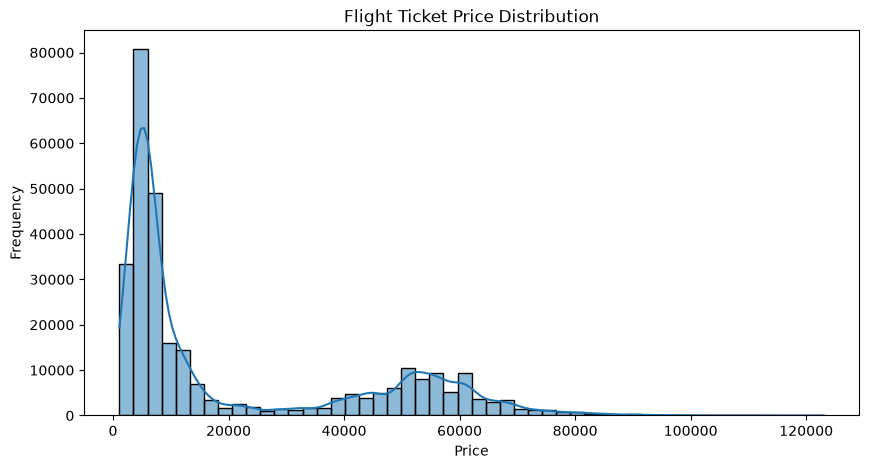

In [18]:
plt.figure(figsize=(10, 5))
sns.histplot(df_clean["price"], bins=50, kde=True)

plt.title("Flight Ticket Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

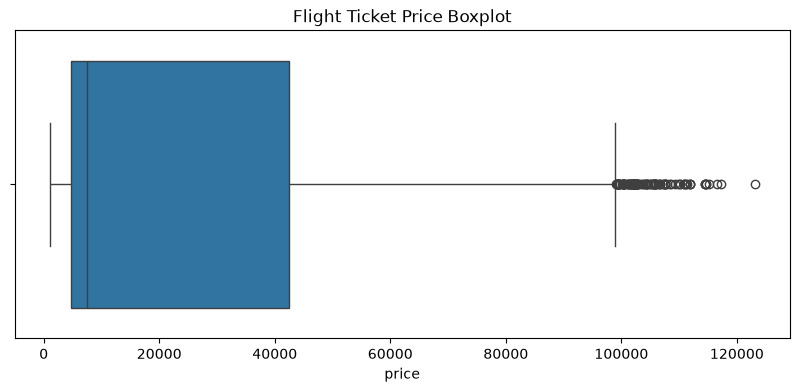

In [19]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_clean["price"])

plt.title("Flight Ticket Price Boxplot")
plt.show()

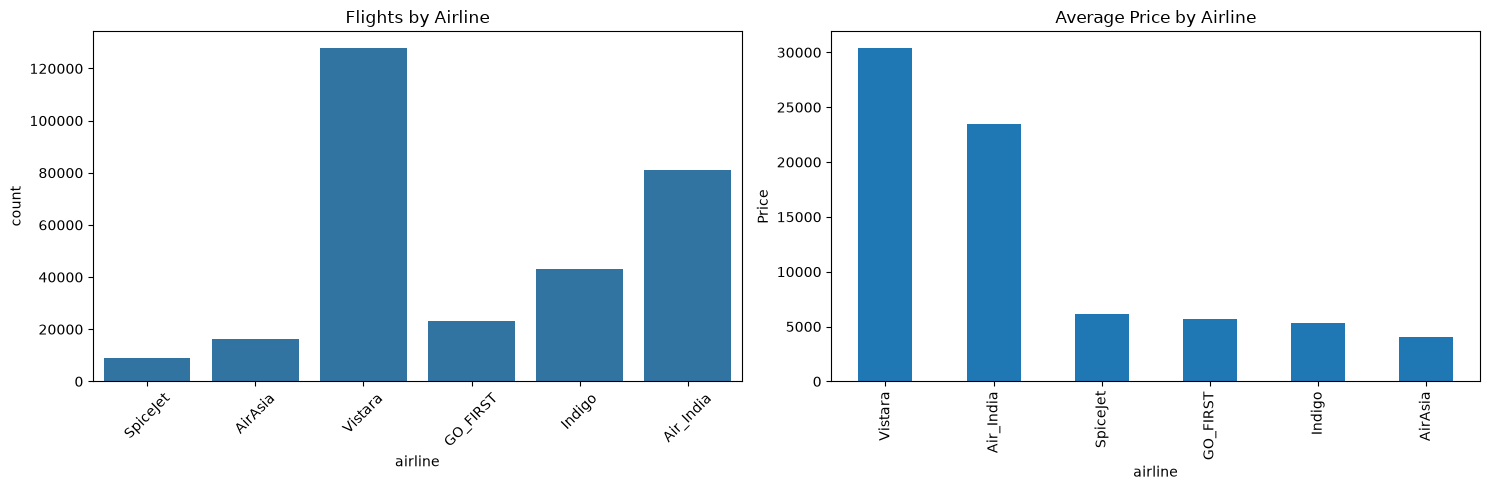

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(data=df_clean, x="airline", ax=ax[0])
ax[0].set_title("Flights by Airline")
ax[0].tick_params(axis="x", rotation=45)

airline_price = df_clean.groupby("airline")["price"].mean().sort_values(ascending=False)
airline_price.plot(kind="bar", ax=ax[1])
ax[1].set_title("Average Price by Airline")
ax[1].set_ylabel("Price")

plt.tight_layout()
plt.show()

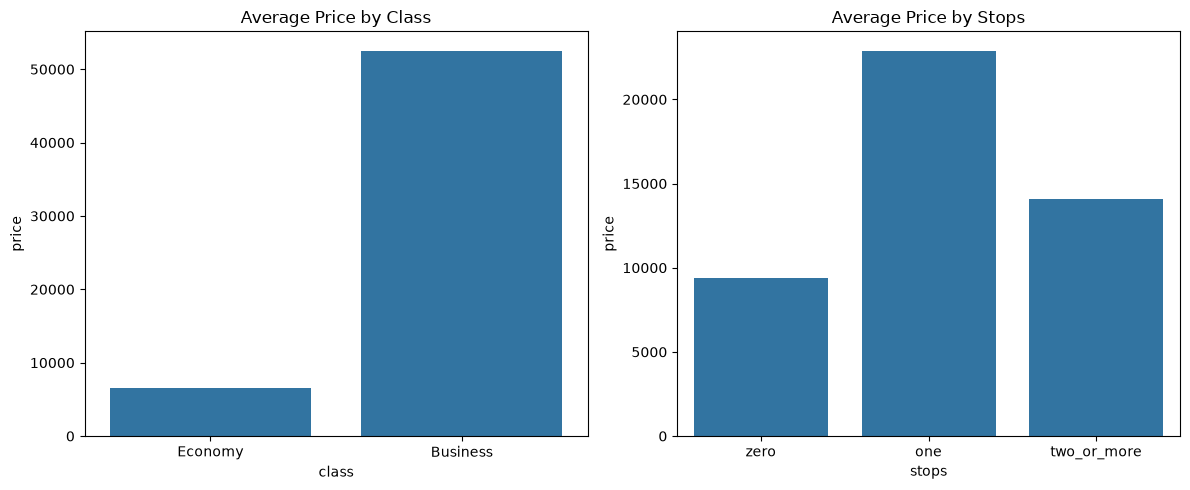

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=df_clean, x="class", y="price", errorbar=None, ax=ax[0])
ax[0].set_title("Average Price by Class")

sns.barplot(data=df_clean, x="stops", y="price", errorbar=None, ax=ax[1])
ax[1].set_title("Average Price by Stops")

plt.tight_layout()
plt.show()

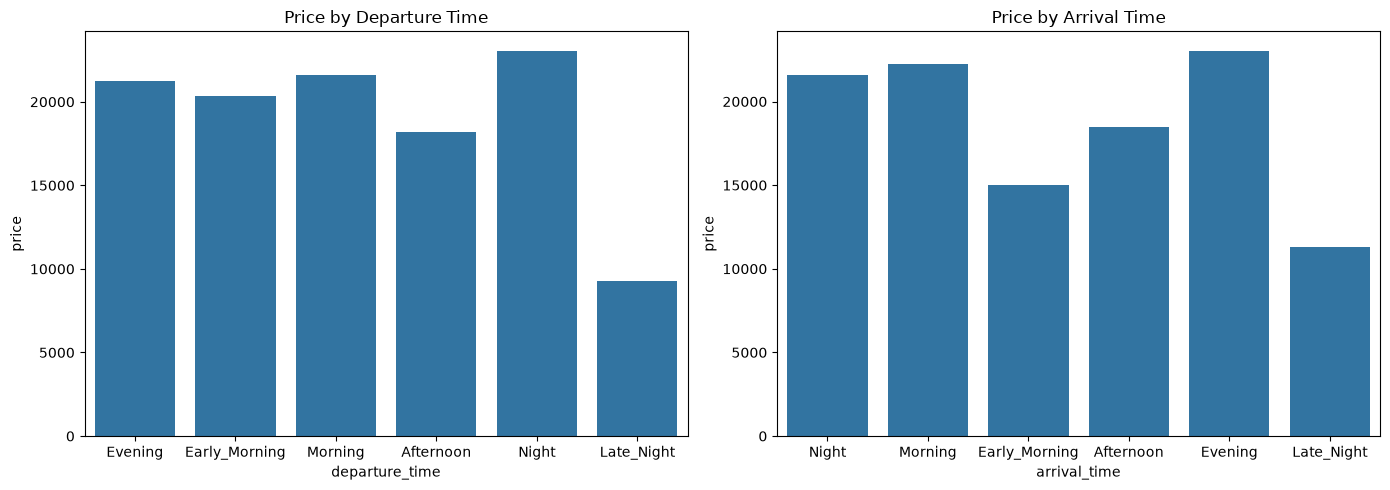

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df_clean, x="departure_time", y="price", errorbar=None, ax=ax[0])
ax[0].set_title("Price by Departure Time")

sns.barplot(data=df_clean, x="arrival_time", y="price", errorbar=None, ax=ax[1])
ax[1].set_title("Price by Arrival Time")

plt.tight_layout()
plt.show()

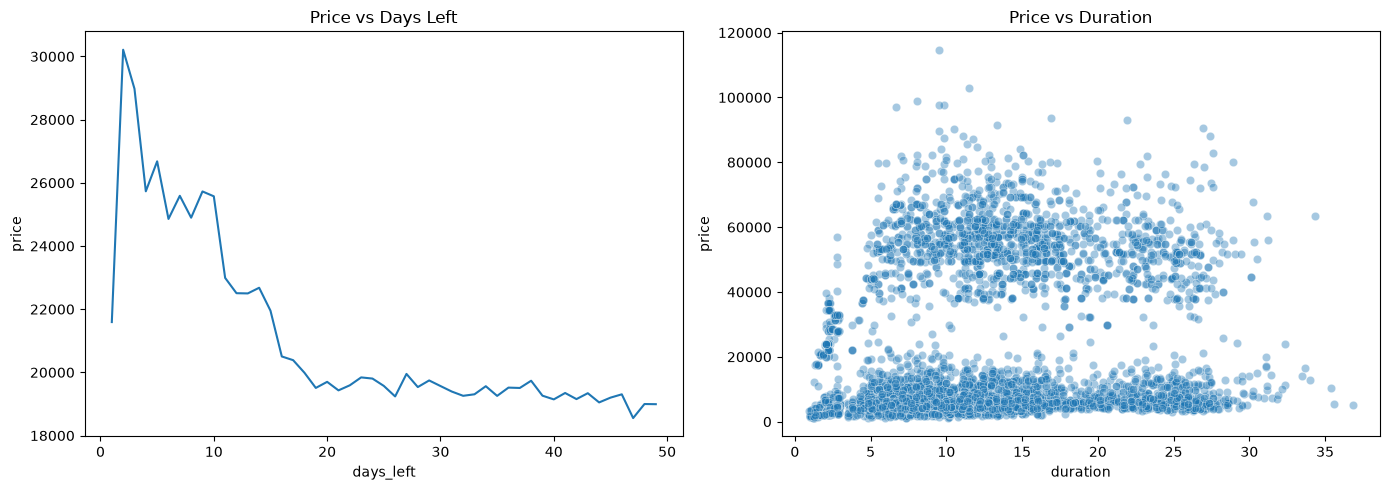

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(data=df_clean, x="days_left", y="price", errorbar=None, ax=ax[0])
ax[0].set_title("Price vs Days Left")

sample_df = df_clean.sample(n=min(5000, len(df_clean)), random_state=42)
sns.scatterplot(data=sample_df, x="duration", y="price", alpha=0.4, ax=ax[1])
ax[1].set_title("Price vs Duration")

plt.tight_layout()
plt.show()

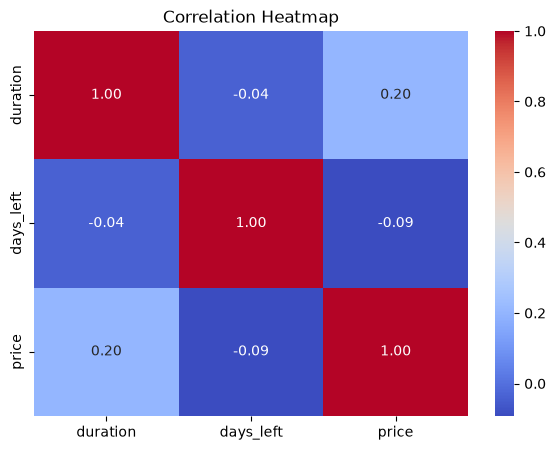

In [24]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    df_clean[["duration", "days_left", "price"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [26]:
X = df_clean[
    ["airline", "source_city", "departure_time", "stops",
     "arrival_time", "destination_city", "class",
     "duration", "days_left"]
]

y = df_clean["price"]

print(X.head())
print(y.head())

    airline source_city departure_time stops   arrival_time destination_city  \
0  SpiceJet       Delhi        Evening  zero          Night           Mumbai   
1  SpiceJet       Delhi  Early_Morning  zero        Morning           Mumbai   
2   AirAsia       Delhi  Early_Morning  zero  Early_Morning           Mumbai   
3   Vistara       Delhi        Morning  zero      Afternoon           Mumbai   
4   Vistara       Delhi        Morning  zero        Morning           Mumbai   

     class  duration  days_left  
0  Economy      2.17          1  
1  Economy      2.33          1  
2  Economy      2.17          1  
3  Economy      2.25          1  
4  Economy      2.33          1  
0    5953
1    5953
2    5956
3    5955
4    5955
Name: price, dtype: int64


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (240122, 9)
Testing data: (60031, 9)


In [28]:
cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", SimpleImputer(strategy="median"), num_cols)
])

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)

print("Linear Regression trained successfully!")

C:\Users\P K SREENIVAS\AppData\Local\Temp\ipykernel_8244\240158470.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns


Linear Regression trained successfully!


In [31]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=5,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [32]:
results = []

for name, predictions in [
    ("Linear Regression", y_pred_linear),
    ("Random Forest", y_pred_rf)
]:
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))

               Model       MAE      RMSE  R2 Score
0  Linear Regression  4553.290  6761.712     0.911
1      Random Forest  2180.885  4027.621     0.969


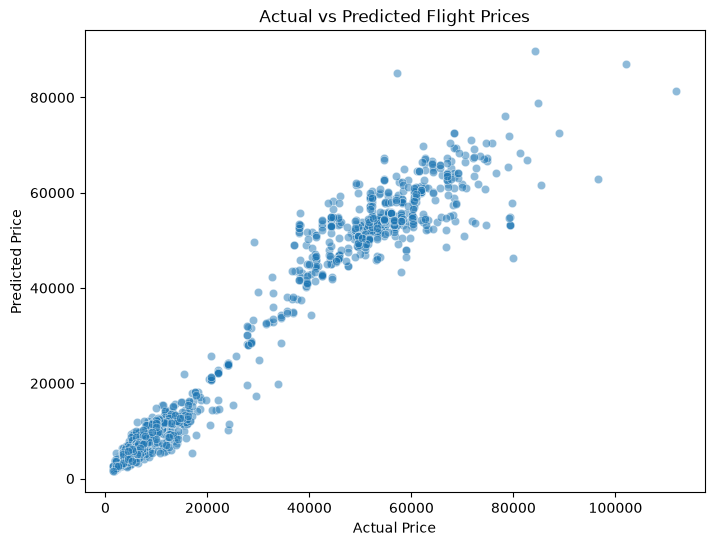

In [33]:
sample = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred_rf
}).sample(n=min(2000, len(y_test)), random_state=42)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=sample,
    x="Actual Price",
    y="Predicted Price",
    alpha=0.5
)

plt.title("Actual vs Predicted Flight Prices")
plt.show()

                        Feature  Importance
34           cat__class_Economy    0.562044
33          cat__class_Business    0.343510
35                num__duration    0.031082
20              cat__stops_zero    0.012838
36               num__days_left    0.011894
5          cat__airline_Vistara    0.010130
1        cat__airline_Air_India    0.004201
8        cat__source_city_Delhi    0.003138
29  cat__destination_city_Delhi    0.002428
18               cat__stops_one    0.001801


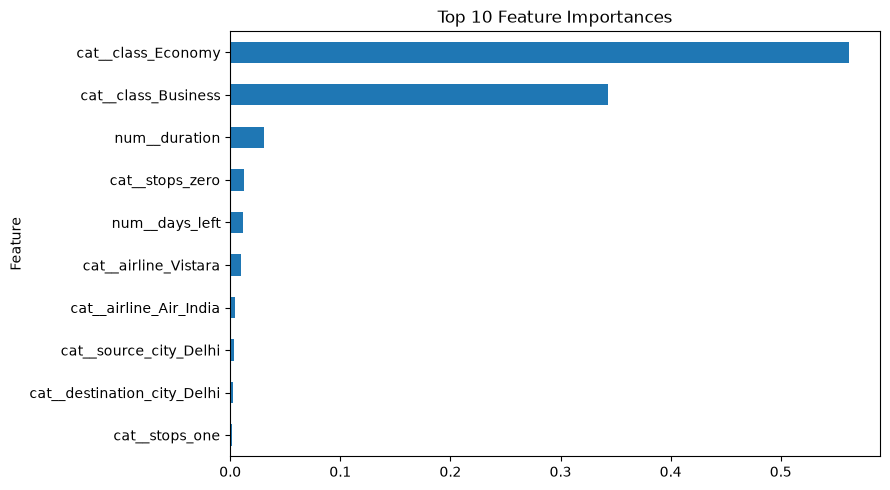

In [34]:
fitted_preprocessor = rf_model.named_steps["preprocessor"]
fitted_rf = rf_model.named_steps["model"]

importance_df = pd.DataFrame({
    "Feature": fitted_preprocessor.get_feature_names_out(),
    "Importance": fitted_rf.feature_importances_
}).sort_values("Importance", ascending=False)

print(importance_df.head(10))

importance_df.head(10).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(9, 5),
    legend=False
)

plt.title("Top 10 Feature Importances")
plt.tight_layout()
plt.show()

In [35]:
import joblib

joblib.dump(rf_model, "flight_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!
